In [1]:
import datetime
import pandas as pd
import lseg.data as ld
import matplotlib.pyplot as plt

In [2]:
ld.open_session()

RICs = ["EUR=", "AUD=", "EURAUD="]
start = datetime.datetime.now() - datetime.timedelta(100)
end = datetime.datetime.now()

In [ ]:
df = ld.get_history(
    universe=RICs,
    fields=["MID_PRICE"],
    interval="30min",
    start=start,
    end=end,
)

df

#df clean on weeknd price

c:\Users\fazru\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lseg\data\_tools\_dataframe.py:177:FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


MID_PRICE,EUR=,AUD=,EURAUD=
Timestamp,,,
2026-04-19 19:00:00,1.1744,0.7141,<NA>
2026-04-19 19:30:00,1.17375,0.71285,<NA>
2026-04-19 20:00:00,1.1739,0.71175,<NA>
2026-04-19 20:30:00,1.1739,0.71245,<NA>
2026-04-19 21:00:00,1.17405,0.7125,<NA>
...,...,...,...
2026-07-27 03:30:00,1.1404,0.69985,1.6295
2026-07-27 04:00:00,1.1403,0.69955,1.63005
2026-07-27 04:30:00,1.1404,0.69965,1.6299


In [4]:
df = df.ffill().dropna()

lookback_norm = 50

eur_norm = df["EUR="] / df["EUR="].rolling(lookback_norm).mean()
aud_norm = df["AUD="] / df["AUD="].rolling(lookback_norm).mean()

spread = eur_norm - aud_norm

lookback_z = 40                          

spread_mean = spread.rolling(lookback_z).mean()
spread_std  = spread.rolling(lookback_z).std()

zscore = (spread - spread_mean) / spread_std

df["spread"] = spread
df["zscore"] = zscore
df = df.dropna()

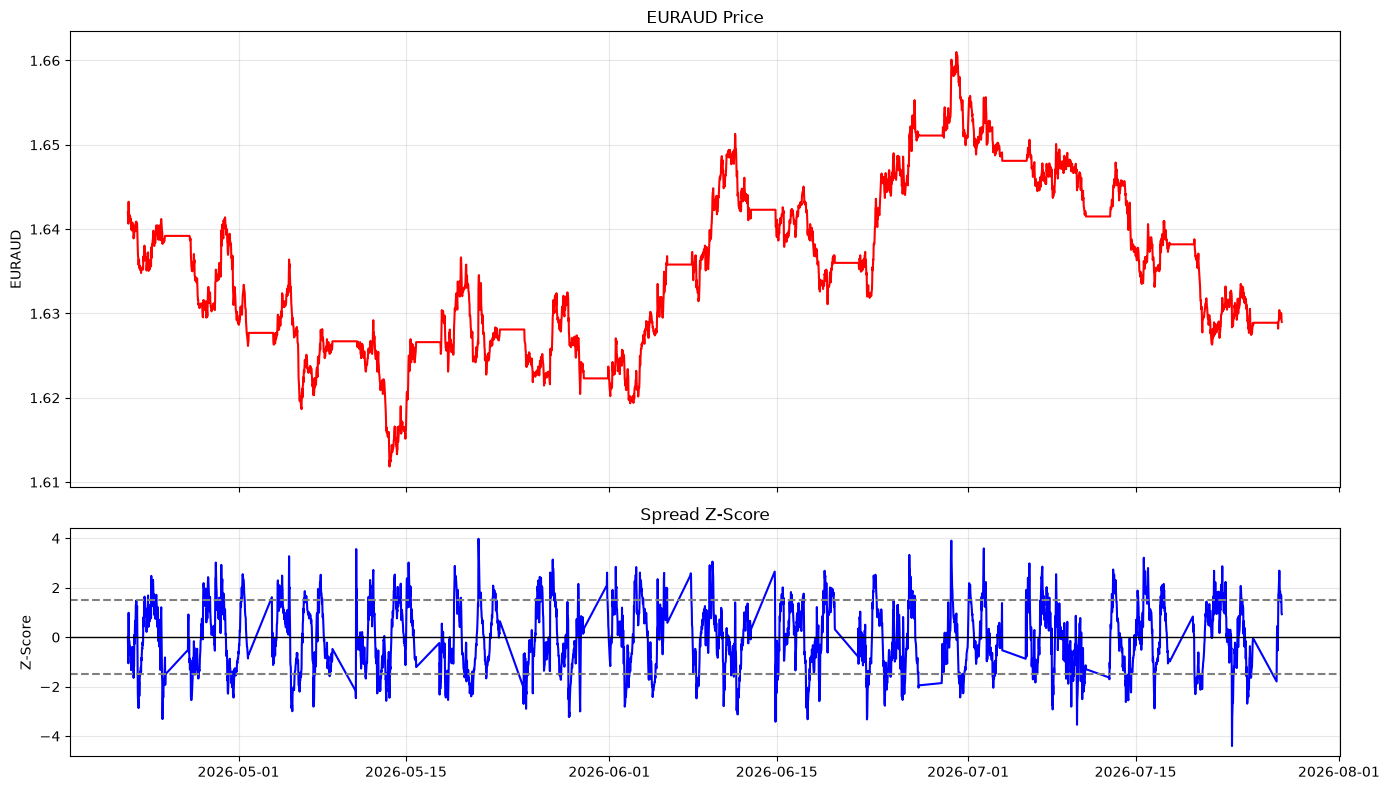

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# EURAUD Price
ax1.plot(df.index, df["EURAUD="], color="red", label="EURAUD")
ax1.set_ylabel("EURAUD")
ax1.set_title("EURAUD Price")
ax1.grid(True, alpha=0.3)

# Z-Score
ax2.plot(df.index, df["zscore"], color="blue", label="Z-Score")
ax2.axhline(0, color="black", lw=1)
ax2.axhline(1.5, color="gray", ls="--")
ax2.axhline(-1.5, color="gray", ls="--")
ax2.set_ylabel("Z-Score")
ax2.set_title("Spread Z-Score")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()